In [45]:
from astropy.io import fits
from astropy.visualization import ZScaleInterval
import astropy.coordinates as coord
from astropy.wcs import WCS
import astropy.units as u
from astroquery.vizier import Vizier
from scipy.optimize import curve_fit
from glob import glob
import cmastro
import pandas as pd
import os
import matplotlib.pyplot as plt
import numpy as np
import pprint

plt.rcParams['image.origin'] = 'lower'

Useful functions for working with .fits files

In [46]:
def read_file(filename):
    image = fits.open("{f}".format(f=filename))[0].data.astype(int)
    return image

def header(filename):
    header = fits.open("{f}".format(f=filename))[0].header
    return header

def view(image, title):
    fig = plt.figure(figsize=(12, 6))
    vmin, vmax = ZScaleInterval().get_limits(image)
    plt.imshow(image, vmin=vmin, vmax=vmax, origin='lower', cmap='cma:lacerta')
    plt.title(title)
    plt.colorbar()
    plt.show()

def get_and_sort_files(folder, extension = 'fts'):
    # Get all .fts files
    files = [y for x in os.walk(folder) for y in glob(os.path.join(x[0], '*.' + extension))]

    # Pick out types of images and sort
    asteroid_files = [f for f in files if "26Proserpina-" in f]
    ast_headers = [header(f) for f in asteroid_files]
    flat_files = [f for f in files if "Flat" in f]
    dark_files = [f for f in files if "Dark" in f]
    bias_files = [f for f in files if "Bias" in f]
    asteroid_files.sort()
    flat_files.sort() 
    dark_files.sort() 
    bias_files.sort()
    return asteroid_files, ast_headers, flat_files, dark_files, bias_files   

**1. Get images categorized by date and type**

In [47]:
# 4 obs nights, 3 astroid images each
folder = "26Proserpina/"
observations = ["20120119", "20120120", "20120122", "20120125"]

# Images paths for each obs night
asteroid1, headers1, flats1, darks1, biases1 = get_and_sort_files(folder + observations[0])
asteroid2, headers2, flats2, darks2, biases2 = get_and_sort_files(folder + observations[1])
asteroid3, headers3, flats3, darks3, biases3 = get_and_sort_files(folder + observations[2])
asteroid4, headers4, flats4, darks4, biases4 = get_and_sort_files(folder + observations[3])

pprint.pprint(headers1[0])


SIMPLE  =                    T                                                  
BITPIX  =                   16 /8 unsigned int, 16 & 32 int, -32 & -64 real     
NAXIS   =                    2 /number of axes                                  
NAXIS1  =                 2048 /fastest changing axis                           
NAXIS2  =                 2048 /next to fastest changing axis                   
BSCALE  =   1.0000000000000000 /physical = BZERO + BSCALE*array_value           
BZERO   =   32768.000000000000 /physical = BZERO + BSCALE*array_value           
DATE-OBS= '2012-01-20T07:27:54' / [ISO 8601] UTC date/time of exposure start    
EXPTIME =   6.00000000000E+001 / [sec] Duration of exposure                     
EXPOSURE=   6.00000000000E+001 / [sec] Duration of exposure                     
SET-TEMP=  -25.000000000000000 /CCD temperature setpoint in C                   
CCD-TEMP=  -25.218294750000005 /CCD temperature at start of exposure in C       
XPIXSZ  =   18.0000000000000

**2. Clean the images**

View all exposures and temperatures

In [48]:
flats = flats1 + flats2 + flats3 + flats4
darks = darks1 + darks2 + darks3 + darks4
biases = biases1 + biases2 + biases3 + biases4
astroids = asteroid1 + asteroid2 + asteroid3 + asteroid4
headers = headers1 + headers2 + headers3 + headers4
for asteroid in astroids:
    exp = header(asteroid)["EXPOSURE"]
    date = header(asteroid)["DATE-OBS"]
    temp = header(asteroid)["CCD-TEMP"]
    print("ASTEROID {d} - Exposure: {e}s, Temp: {t}".format(d=date, e=exp, t=temp))
print("-----------------------------")
for flat in flats:
    exp = header(flat)["EXPOSURE"]
    date = header(flat)["DATE-OBS"]
    temp = header(flat)["CCD-TEMP"]
    print("FLAT {d} - Exposure: {e}s, Temp: {t}".format(d=date, e=exp, t=temp))
print("-----------------------------")
for dark in darks:
    exp = header(dark)["EXPOSURE"]
    date = header(dark)["DATE-OBS"]
    temp = header(dark)["CCD-TEMP"]
    print("DARK {d} - Exposure: {e}s, Temp: {t}".format(d=date, e=exp, t=temp))
print("-----------------------------")
for bias in biases:
    exp = header(bias)["EXPOSURE"]
    date = header(bias)["DATE-OBS"]
    temp = header(bias)["CCD-TEMP"]
    print("BIAS {d} - Exposure: {e}s, Temp: {t}".format(d=date, e=exp, t=temp))

ASTEROID 2012-01-20T07:27:54 - Exposure: 60.0s, Temp: -25.218294750000005
ASTEROID 2012-01-20T07:29:21 - Exposure: 60.0s, Temp: -25.108281000000005
ASTEROID 2012-01-20T07:30:48 - Exposure: 60.0s, Temp: -25.117710750000004
ASTEROID 2012-01-21T07:39:37 - Exposure: 60.0s, Temp: -25.114567500000007
ASTEROID 2012-01-21T07:41:03 - Exposure: 60.0s, Temp: -25.023413250000004
ASTEROID 2012-01-21T07:42:29 - Exposure: 60.0s, Temp: -25.06113225
ASTEROID 2012-01-23T08:35:52 - Exposure: 60.0s, Temp: -25.183719
ASTEROID 2012-01-23T08:37:18 - Exposure: 60.0s, Temp: -25.14914325
ASTEROID 2012-01-23T08:38:44 - Exposure: 60.0s, Temp: -25.139713500000006
-----------------------------
FLAT 2012-01-20T00:44:14 - Exposure: 1.75s, Temp: -4.702302
FLAT 2012-01-20T00:44:28 - Exposure: 2.07s, Temp: -4.3691175
FLAT 2012-01-20T00:44:42 - Exposure: 2.21s, Temp: -3.9573517500000004
FLAT 2012-01-20T00:44:56 - Exposure: 2.35s, Temp: -3.62416725
FLAT 2012-01-20T00:45:10 - Exposure: 2.5s, Temp: -3.2092582500000004
FLAT 

For the first, night the temperature controller was apparently off when taking the darks, so master dark will be from only 2/3 nights.

In [49]:
flats = [flat for flat in flats if header(flat)["CCD-Temp"] < -15]

We only want 60s darks to match our sky images. Now to create median images to use for cleaning

In [50]:
darks60 = [dark for dark in darks if np.abs(header(dark)["EXPOSURE"] - 60) <= 1]
print(darks60)

['26Proserpina/20120119/Calibration/Dark-S001-R003-C001-B2.fts', '26Proserpina/20120119/Calibration/Dark-S001-R003-C002-B2.fts', '26Proserpina/20120119/Calibration/Dark-S001-R003-C003-B2.fts', '26Proserpina/20120119/Calibration/Dark-S001-R003-C004-B2.fts', '26Proserpina/20120119/Calibration/Dark-S001-R003-C005-B2.fts', '26Proserpina/20120120/Calibration/Dark-S001-R003-C001-B2.fts', '26Proserpina/20120120/Calibration/Dark-S001-R003-C002-B2.fts', '26Proserpina/20120120/Calibration/Dark-S001-R003-C003-B2.fts', '26Proserpina/20120120/Calibration/Dark-S001-R003-C004-B2.fts', '26Proserpina/20120120/Calibration/Dark-S001-R003-C005-B2.fts', '26Proserpina/20120122/Calibration/Dark-S001-R003-C001-B2.fts', '26Proserpina/20120122/Calibration/Dark-S001-R003-C002-B2.fts', '26Proserpina/20120122/Calibration/Dark-S001-R003-C003-B2.fts', '26Proserpina/20120122/Calibration/Dark-S001-R003-C004-B2.fts', '26Proserpina/20120122/Calibration/Dark-S001-R003-C005-B2.fts', '26Proserpina/20120125/Calibration/Dark

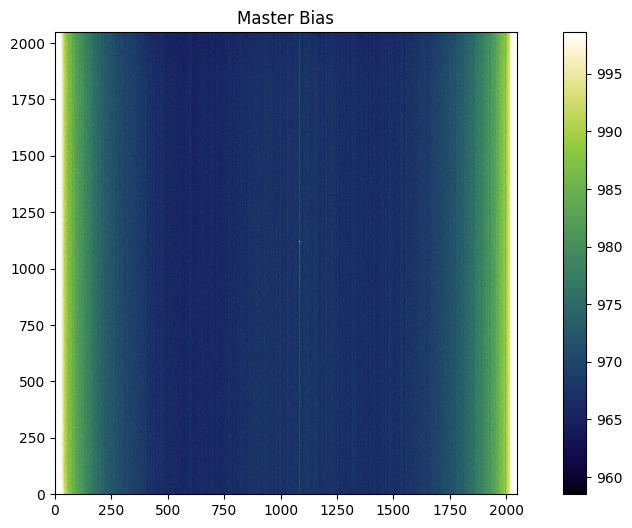

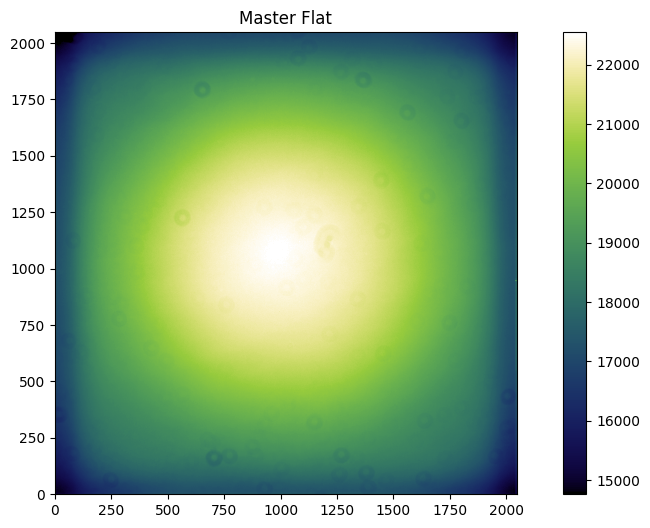

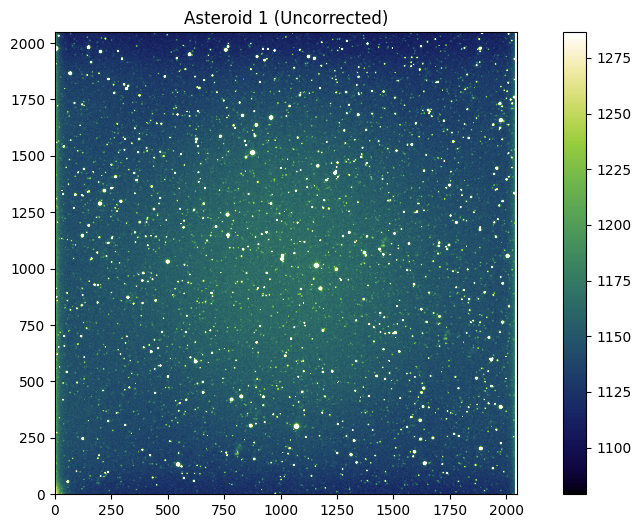

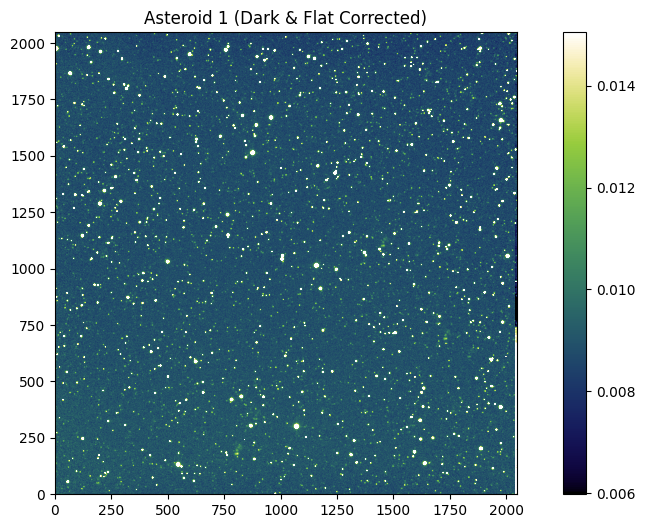

In [51]:
# Numpy arrays of images
all_astroid_np = np.array([read_file(f) for f in astroids])
all_biases_np = np.array([read_file(f) for f in biases])
all_dark60_np = np.array([read_file(f) for f in darks60])
all_flat_np = np.array([read_file(f) for f in flats])

# Flip science images
all_astroid_np = [all_astroid_np[::-1,::-1] for all_astroid_np in all_astroid_np]

# Median combine darks
master_dark = np.median(all_dark60_np, axis=0)
master_flat = np.median(all_flat_np, axis=0)
master_bias = np.median(all_biases_np, axis=0)

view(master_bias, "Master Bias")
view(master_flat, "Master Flat")

science_imgs = ((all_astroid_np - master_dark) / (master_flat))
view(all_astroid_np[0], "Asteroid 1 (Uncorrected)")
view(science_imgs[0], "Asteroid 1 (Dark & Flat Corrected)")

**Crossmatching Stars**

Centroid Finding Algorithm

In [91]:
def star_gaussian(stars, image, plot=False):
    centroids_x_coords = []
    centroids_y_coords = []
    failed_fittings = 0
    size = 20
    # 2d gaussian
    def gauss(xy, a, x0, y0, sigma_x, sigma_y, c):
        x, y = xy
        g = a*np.exp(-(x-x0)**2/(2*sigma_x**2) - (y-y0)**2/(2*sigma_y**2)) + c
        return g.ravel()

    for i in range(len(stars[0])):
        box = image[stars[0][i]-size:stars[0][i]+size, stars[1][i]-size:stars[1][i]+size]
        
        # Create coordinate matrices and flatten them for fitting
        xx, yy = np.meshgrid(np.arange(box.shape[1]), np.arange(box.shape[0])) 
        xx_flat = xx.ravel()
        yy_flat = yy.ravel()

        # Use centroid equation for initial guess
        x = np.sum(xx * box) / np.sum(box) 
        y = np.sum(yy * box) / np.sum(box) 

        # Fit Gaussian
        if len(yy_flat) != 0:
            try:
                initial_guess = (1,x,y,1,1,0)
                popt, pcov = curve_fit(gauss, (xx_flat, yy_flat), box.ravel(), p0=initial_guess)
                # get new centroid
                centroid_x, centroid_y = popt[1], popt[2]
                # put the coords back in the original context of the image
                x = stars[1][i] - size
                y = stars[0][i] - size
                centroid_x += stars[1][i] - size
                centroid_y += stars[0][i] - size
                        # If you want some plot
                if plot and i%120==0:
                    fig = plt.figure(figsize=(7,7))
                    plt.figure(figsize=(7,7))
                    vmin,vmax = ZScaleInterval().get_limits(box)
                    plt.scatter(x, y , marker='x', color='blue', label="Initial Centroid")
                    plt.scatter(centroid_x, centroid_y, marker='x', color='red', label="Gaussian Centroid")
                    plt.xlabel("Pixels")
                    plt.ylabel("Pixels")
                    plt.imshow(image, vmin=vmin, vmax=vmax, cmap='cma:lacerta', origin='lower')
                    plt.legend(loc='best')
                    plt.title('Star Centroid')
                print(f"Inital Centroid: {x}, {y}")
                print(f"Gaussian Centroid: {centroid_x}, {centroid_y}")
                
                # add centroids to list of coords
                centroids_x_coords.append(centroid_x)
                centroids_y_coords.append(centroid_y)
                
                
            except RuntimeError:
                failed_fittings += 1
                
    print(f"Couldn't fit {failed_fittings} stars")
    return centroids_x_coords, centroids_y_coords

Applying to all stars

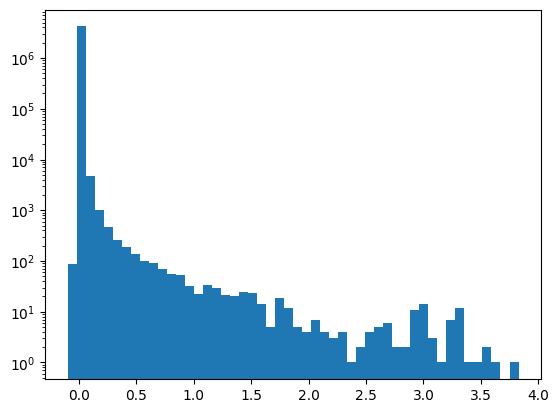

In [53]:
plt.hist(science_imgs[0].flatten(), bins=50)
plt.yscale('log')

Inital Centroid: 36, 33
Gaussian Centroid: 56.138611486657695, 53.94163591838236
Inital Centroid: 37, 33
Gaussian Centroid: 56.13861099030615, 53.94163644666129
Inital Centroid: 36, 34
Gaussian Centroid: 56.138611985618894, 53.94163520731304
Inital Centroid: 37, 34
Gaussian Centroid: 56.13861188089625, 53.94163545816761
Inital Centroid: 36, 35
Gaussian Centroid: 56.13861085101672, 53.94163676173387
Inital Centroid: 525, 107
Gaussian Centroid: 544.9864102767394, 131.07411337397124
Inital Centroid: 523, 108
Gaussian Centroid: 544.9864123682316, 131.07411163187112
Inital Centroid: 524, 108
Gaussian Centroid: 544.9864104038195, 131.07411326464714
Inital Centroid: 525, 108
Gaussian Centroid: 544.9864097271451, 131.07411382480126
Inital Centroid: 526, 108
Gaussian Centroid: 544.9864097802613, 131.0741137772744
Inital Centroid: 527, 108
Gaussian Centroid: 544.9864095931471, 131.07411392825423
Inital Centroid: 522, 109
Gaussian Centroid: 544.9864165152003, 131.0741081666045
Inital Centroid: 52

/tmp/ipykernel_124305/603708091.py:21: RuntimeWarning: invalid value encountered in scalar divide
  x = np.sum(xx * box) / np.sum(box)
/tmp/ipykernel_124305/603708091.py:22: RuntimeWarning: invalid value encountered in scalar divide
  y = np.sum(yy * box) / np.sum(box)


Couldn't fit 17 stars


<Figure size 700x700 with 0 Axes>

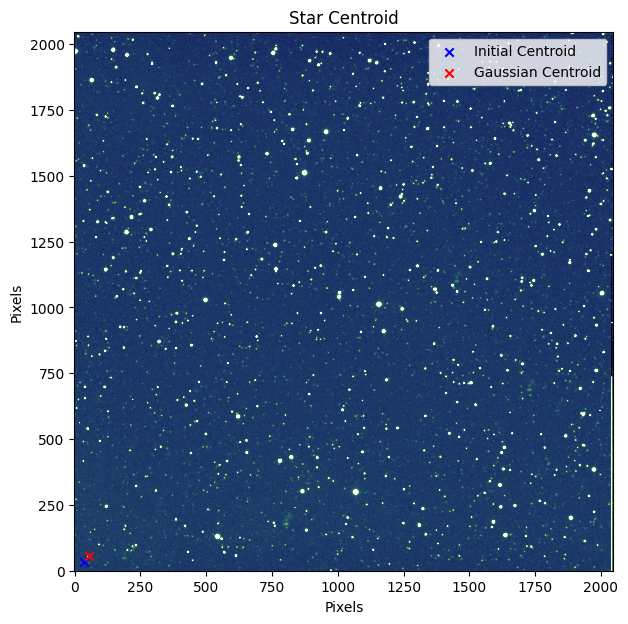

<Figure size 700x700 with 0 Axes>

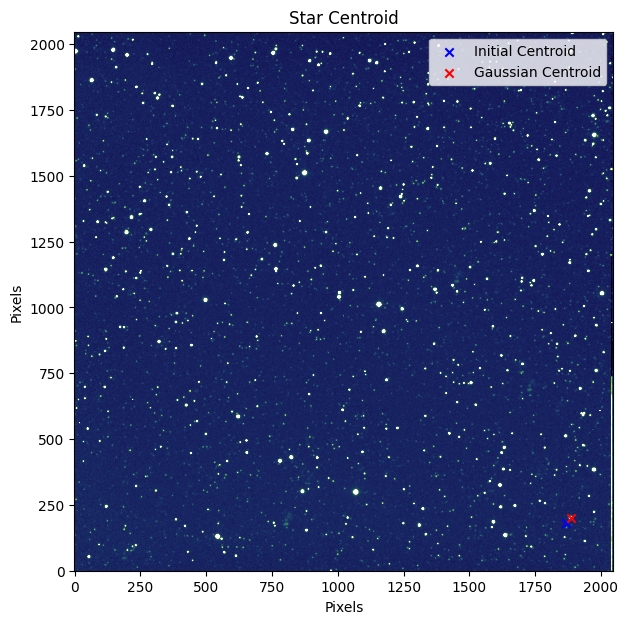

<Figure size 700x700 with 0 Axes>

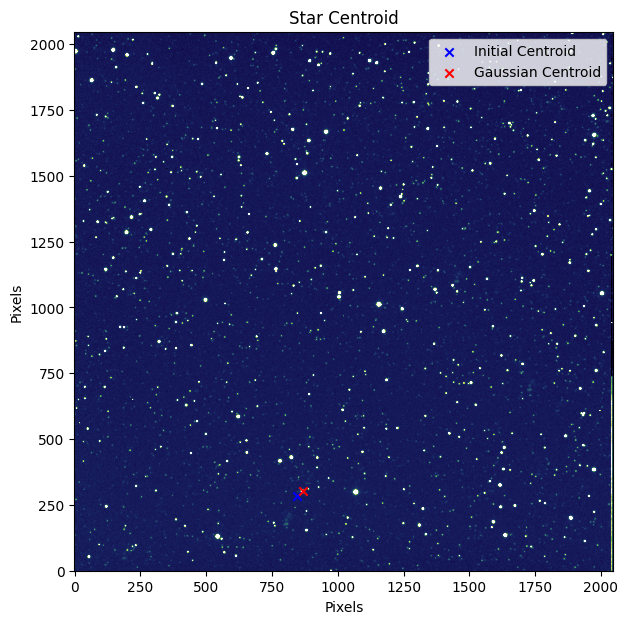

<Figure size 700x700 with 0 Axes>

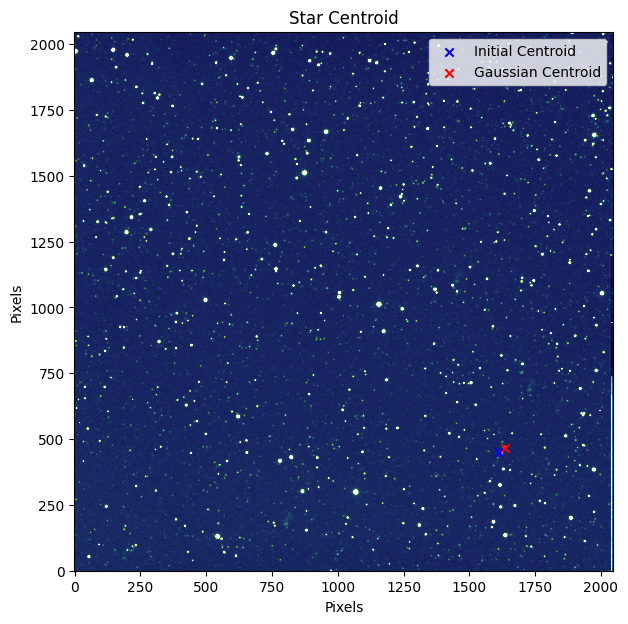

<Figure size 700x700 with 0 Axes>

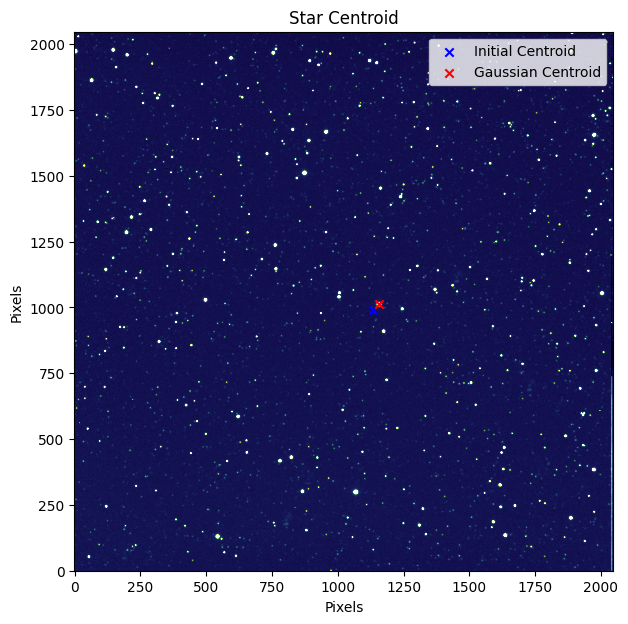

<Figure size 700x700 with 0 Axes>

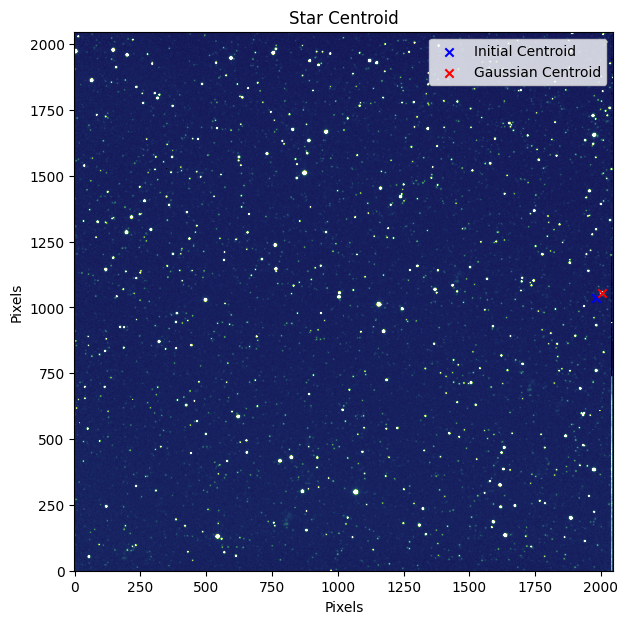

<Figure size 700x700 with 0 Axes>

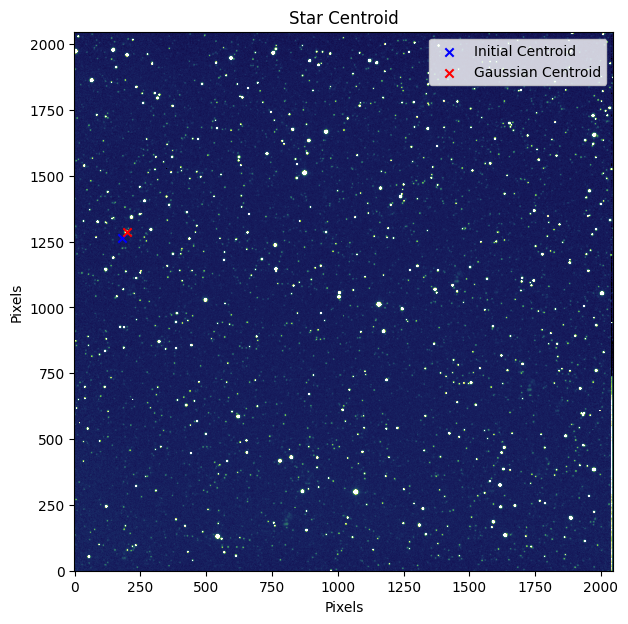

<Figure size 700x700 with 0 Axes>

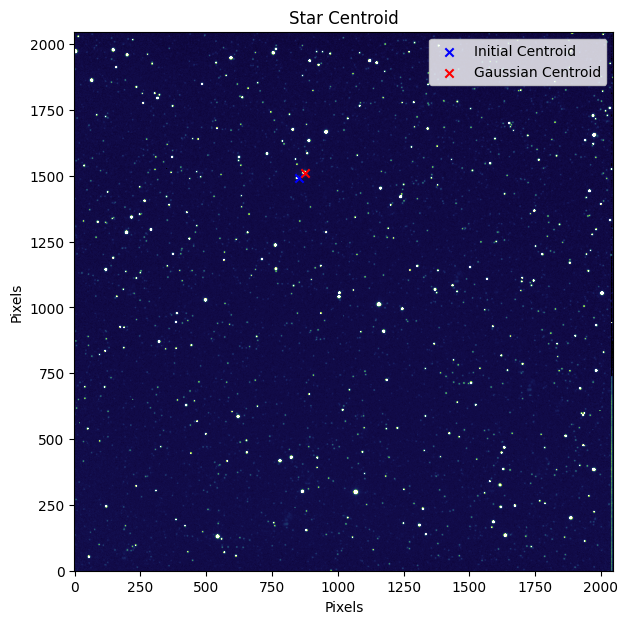

<Figure size 700x700 with 0 Axes>

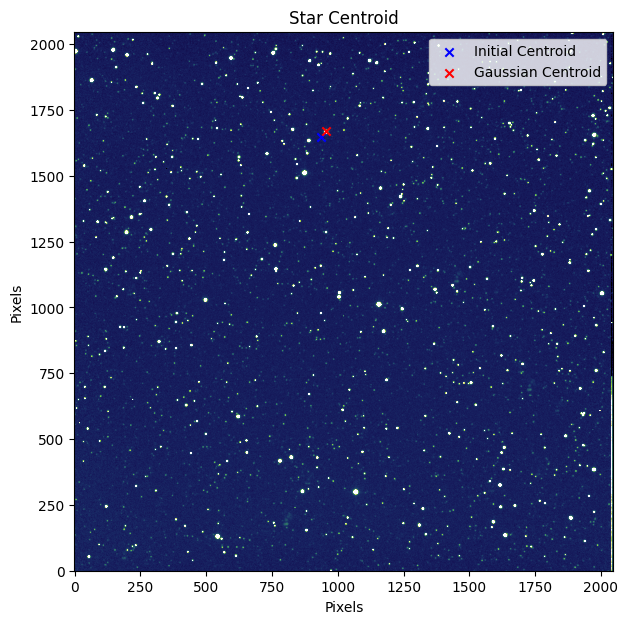

<Figure size 700x700 with 0 Axes>

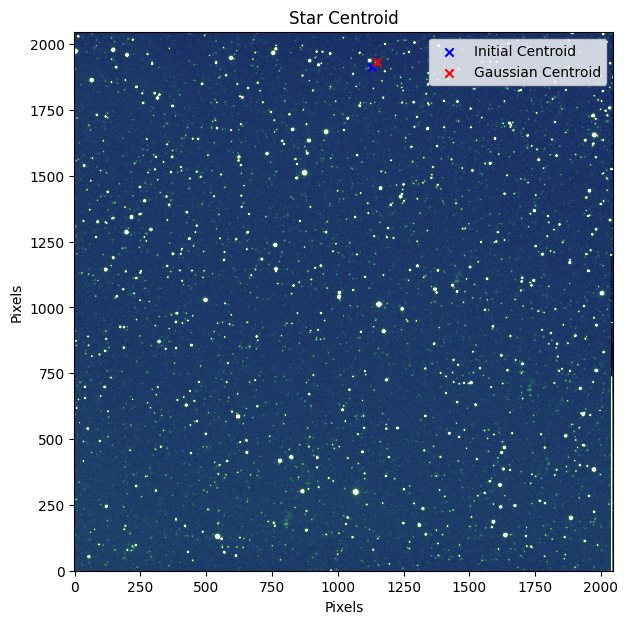

In [92]:
threshold = .3
stars = np.where(science_imgs[0] > threshold)
centroid_x, centroid_y = star_gaussian(stars, science_imgs[0], plot=True)

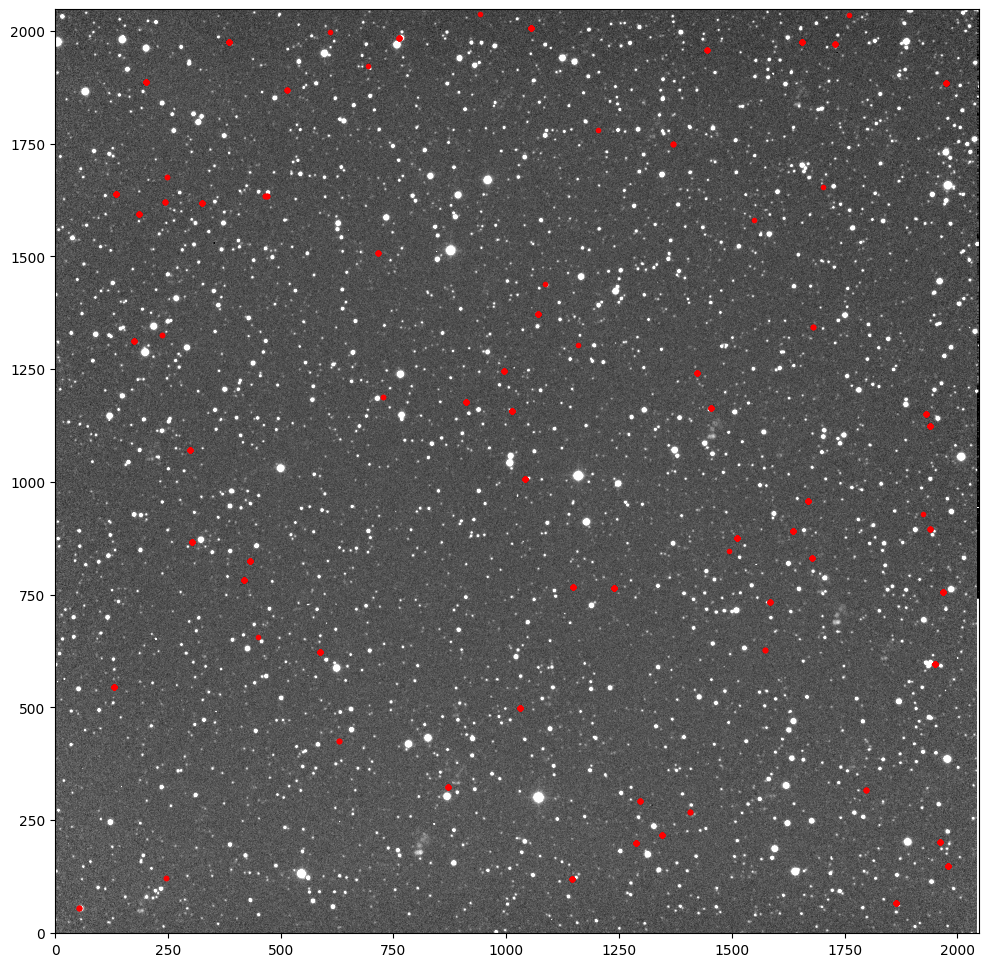

In [93]:

fig = plt.figure(figsize=(24, 12))
vmin, vmax = ZScaleInterval().get_limits(science_imgs[0])
plt.imshow(science_imgs[0], vmin=vmin, vmax=vmax, origin='lower', cmap='gray')
plt.scatter(centroid_y,centroid_x, marker='.', color='red', label="Centroids")

Getting USNO coordinates

In [55]:
# Get center of field and query USNO-B1 with 38 arcmin width
cof = coord.SkyCoord(header(astroids[0])['CRVAL1'], header(astroids[0])['CRVAL2'], unit=(u.deg, u.deg))
fov = 36.2 * u.arcmin
Vizier.ROW_LIMIT = -1
usno = Vizier.query_region(cof, width=fov, height=fov, catalog='USNO-B1')[0].to_pandas()

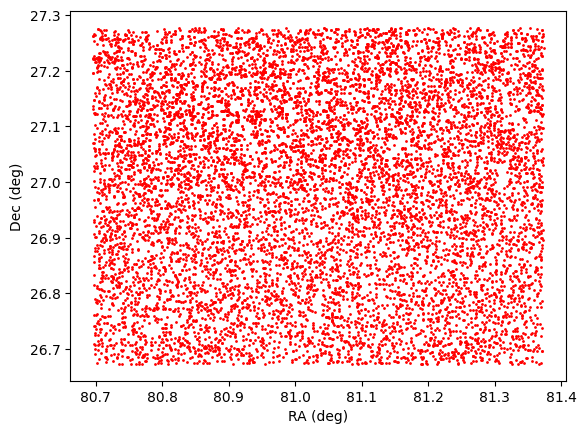

In [56]:
plt.scatter(usno['RAJ2000'], usno['DEJ2000'], s=1, color='red')
plt.xlabel('RA (deg)')
plt.ylabel('Dec (deg)')
plt.show()

(array([  0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   2.,   0.,
          0.,   0.,   1.,   1.,   1.,   0.,   1.,   2.,   3.,   4.,   5.,
          2.,   2.,   3.,   5.,   2.,   5.,   1.,   2.,   3.,   4.,   3.,
          5.,   3.,   9.,   6.,  15.,  14.,   7.,  17.,  21.,  21.,  24.,
         28.,  34.,  31.,  38.,  34.,  47.,  52.,  53.,  58.,  71.,  56.,
         79.,  81.,  83.,  89.,  89., 126., 134., 133., 126., 141., 143.,
        169., 196., 182., 190., 150., 177., 171., 183., 223., 238., 274.,
        301., 282., 342., 379., 412., 472., 526., 628., 719., 953., 333.,
        316.]),
 array([ 7.        ,  7.13000011,  7.26000023,  7.38999987,  7.51999998,
         7.6500001 ,  7.78000021,  7.90999985,  8.03999996,  8.17000008,
         8.30000019,  8.43000031,  8.56000042,  8.68999958,  8.81999969,
         8.94999981,  9.07999992,  9.21000004,  9.34000015,  9.47000027,
         9.60000038,  9.72

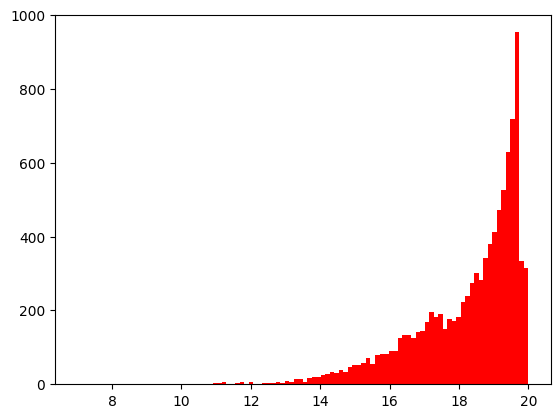

In [57]:
plt.hist(usno['R2mag'], bins=100, color='red', range=(7,20))

38


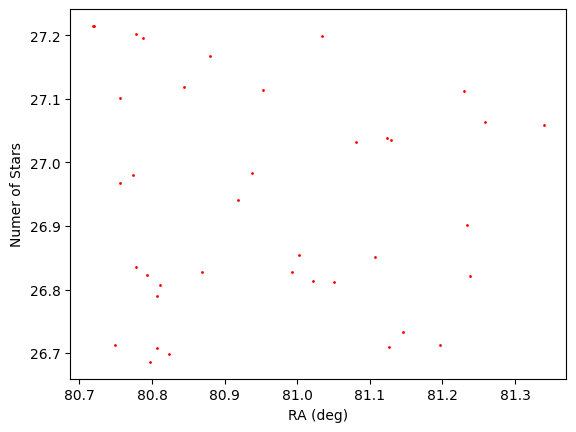

In [74]:
mag_limit = 20
usno_reduced = usno[usno['R2mag'] > mag_limit].reset_index(drop=True)
print(len(usno_reduced))

plt.scatter(usno_reduced['RAJ2000'], usno_reduced['DEJ2000'], s=1, color='red')
plt.xlabel('RA (deg)')
plt.ylabel('Numer of Stars')
plt.show()

Converting USNO RA/DEC positions into pixel coordinates

In [59]:
def initial_transform(usno_coords, image_shape, focal_length, pixel_size, rotation, center_of_field, x_offset, y_offset):
    
    alpha = np.deg2rad(usno_coords[:,0])
    delta = np.deg2rad(usno_coords[:,1])
                       
    alpha_0 = center_of_field.ra.rad
    delta_0 = center_of_field.dec.rad
    
    print(alpha_0, delta_0)
    # Project to X and Y
    X = (np.cos(delta)*np.sin(alpha - alpha_0))/((np.cos(delta_0))*np.cos(delta)*np.cos(alpha-alpha_0)+np.sin(delta)*np.sin(delta_0))
    Y = (np.sin(delta_0)*np.cos(delta)*np.cos(alpha-alpha_0)-np.cos(delta_0)*np.sin(delta))/(np.cos(delta_0)*np.cos(delta)*np.cos(alpha-alpha_0)+np.sin(delta)*np.sin(delta_0))
    
    x_offset = 1024
    y_offset = 1024
    
    # Convert to pixels
    x = (focal_length*X)/pixel_size + x_offset
    y = (focal_length*Y)/pixel_size + y_offset 
    return x, y

1.4143189109504555 0.47080733517624535


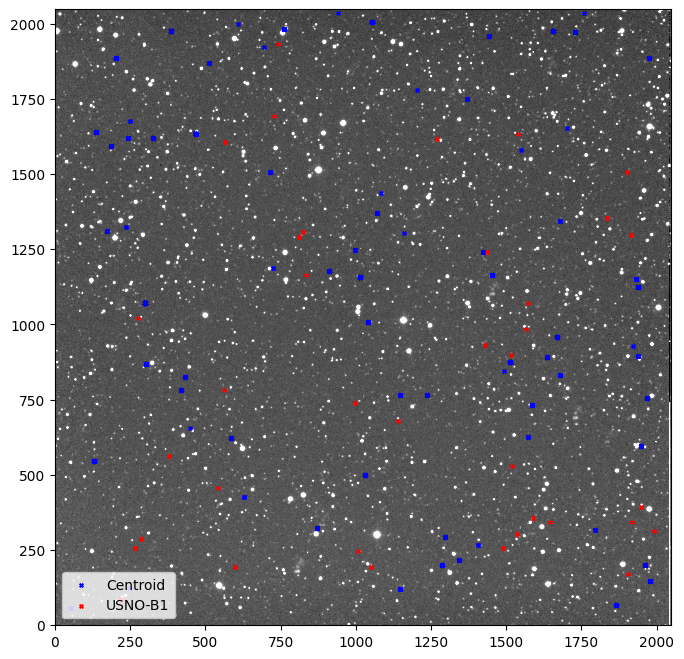

In [77]:
pixel_size = 0.018 # mm
image_shape = (2048, 2048) # after binning
focal_length = 3454 # mm F/6.8
rotation = 0
x_offset = 0
y_offset = 0
usno_stars = np.vstack((usno_reduced['RAJ2000'], usno_reduced['DEJ2000'])).T

approximate_x, approximate_y = initial_transform(usno_stars, image_shape, focal_length, pixel_size, rotation, cof, x_offset, y_offset)
usno_reduced['approx_x'] = approximate_x
usno_reduced['approx_y'] = approximate_y

fig = plt.figure(figsize=(8, 8))
vmin, vmax = ZScaleInterval().get_limits(science_imgs[0])
plt.imshow(science_imgs[0], cmap='gray', origin='lower', vmin=vmin, vmax=vmax)
plt.scatter(centroid_y, centroid_x, marker='x' , color ='blue', s=7, label='Centroid')
plt.scatter(usno_reduced['approx_y'], usno_reduced['approx_x'], marker='x', s=7, color='red', label='USNO-B1')
plt.legend(loc='best')
plt.show()

